# SAM2UNet Kaggle Trainer with Augmentation + Distance Transform Auxiliary Training

Train SAM2UNet variants using **OpenEarthMap + Optional OSM road masks** with distance-transform auxiliary training and advanced augmentation.

**Features:**
- First run: baseline without OSM data
- Then sweep distance-transform auxiliary training with lambda 0.5 and max distances 3.0, 6.0, and 10.0
- Dual-output training: OEM (9-class) + OSM (binary roads) when OSM is enabled
- Combined loss: `Loss_total = Loss_OEM + lambda * Loss_OSM`
- Distance-transform weighting on the OSM loss for the auxiliary runs
- Flexible dataset: Falls back to OEM-only when OSM is disabled
- Seed-controlled random augmentations (HFlip, VFlip, Rotate90, Brightness/Contrast)
- Early stopping to prevent overfitting
- Memory-safe training (reduced batch size for large variant)
- Metrics: Precision, Recall, F1-Score, mIoU, Boundary IoU
- Learning curves and convergence plots for all runs
- Per-run training history export

## Configuration & Paths

In [1]:
import os
import sys
import json
import math
import shutil
import subprocess
from pathlib import Path

# ==============================================================================
# SEED - Set this to control random behavior
# ==============================================================================
SEED = 42

# ==============================================================================
# User-configurable paths
# ==============================================================================
OPENEARTHMAP_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/OpenEarthMap/OpenEarthMap_wo_xBD')
TRAIN_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/train.txt')
VAL_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/val.txt')
TEST_TXT_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/test.txt')

OSM_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/openstreetmap-data/roads/roads/binary_masks')
SAM_CHECKPOINTS_DATASET_PATH = Path('/kaggle/input/datasets/tiagosantos71921/sam-checkpoints')

# ==============================================================================
# Training configuration
# ==============================================================================
MODEL_VARIANTS = ['tiny']#, 'small', 'base'] #, 'large'] # 'large' disabled for now
ROAD_CLASS_INDEX = 4
EPOCHS = 150
EVAL_EVERY = 1
IMAGE_SIZE = 512
NUM_CLASSES = 9
BATCH_SIZE_DEFAULT = 4
BATCH_SIZE_LARGE = 2
LR = 1e-3
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
EARLY_STOP_PATIENCE = 10
EARLY_STOP_MIN_DELTA = 0.0001

# OSM Configuration
TINY_LAMBDA_CANDIDATES = [0.5]
DT_MAX_DISTANCE_CANDIDATES = [3.0, 6.0, 10.0]
OSM_LAMBDA = 0.5 # Default fallback

MAX_OUTPUT_GB = 19.0
PRUNE_TO_LAST_IF_OVER_LIMIT = True

KAGGLE = Path('/kaggle').exists()
WORK_DIR = Path('/kaggle/working/sam2unet_augmented_osm_run') if KAGGLE else Path('./sam2unet_augmented_osm_run')
OUTPUT_DIR = WORK_DIR / 'outputs'
HISTORY_DIR = WORK_DIR / 'history'

WORK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

if 'YOUR_OPENEARTHMAP_DATASET' in str(OPENEARTHMAP_DATASET_PATH): OPENEARTHMAP_DATASET_PATH = None
if 'YOUR_SAM2_CHECKPOINTS' in str(SAM_CHECKPOINTS_DATASET_PATH): SAM_CHECKPOINTS_DATASET_PATH = None
if 'your-osm-road-masks' in str(OSM_DATASET_PATH): OSM_DATASET_PATH = None

print('=' * 80)
print('CONFIGURATION (WITH DISTANCE TRANSFORM AUXILIARY TRAINING)')
print('=' * 80)
print(f'Python: {sys.version}')
print(f'Kaggle runtime: {KAGGLE}')
print(f'Seed: {SEED}')
print(f'WORK_DIR: {WORK_DIR}')
print(f'OUTPUT_DIR: {OUTPUT_DIR}')
print(f'OPENEARTHMAP_DATASET_PATH: {OPENEARTHMAP_DATASET_PATH}')
print(f'OSM_DATASET_PATH: {OSM_DATASET_PATH}')
print(f'SAM_CHECKPOINTS_DATASET_PATH: {SAM_CHECKPOINTS_DATASET_PATH}')
print(f'MODEL_VARIANTS: {MODEL_VARIANTS}')
print(f'TINY_LAMBDA_CANDIDATES: {TINY_LAMBDA_CANDIDATES}')
print(f'DT_MAX_DISTANCE_CANDIDATES: {DT_MAX_DISTANCE_CANDIDATES}')
print(f'EPOCHS: {EPOCHS} | EVAL_EVERY: {EVAL_EVERY}')
print(f'EARLY_STOP_PATIENCE: {EARLY_STOP_PATIENCE}')
print(f'BATCH_SIZE: {BATCH_SIZE_DEFAULT}')
print('=' * 80)

CONFIGURATION (WITH DISTANCE TRANSFORM AUXILIARY TRAINING)
Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Kaggle runtime: True
Seed: 42
WORK_DIR: /kaggle/working/sam2unet_augmented_osm_run
OUTPUT_DIR: /kaggle/working/sam2unet_augmented_osm_run/outputs
OPENEARTHMAP_DATASET_PATH: /kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/OpenEarthMap/OpenEarthMap_wo_xBD
OSM_DATASET_PATH: /kaggle/input/datasets/tiagosantos71921/openstreetmap-data/roads/roads/binary_masks
SAM_CHECKPOINTS_DATASET_PATH: /kaggle/input/datasets/tiagosantos71921/sam-checkpoints
MODEL_VARIANTS: ['tiny']
TINY_LAMBDA_CANDIDATES: [0.5]
DT_MAX_DISTANCE_CANDIDATES: [3.0, 6.0, 10.0]
EPOCHS: 150 | EVAL_EVERY: 1
EARLY_STOP_PATIENCE: 10
BATCH_SIZE: 4


## 2. Configuration

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import random
import albumentations as A

# Set random seeds for reproducibility
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

torch.set_float32_matmul_precision('high')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

if torch.cuda.is_available():
    print(f'GPU count: {torch.cuda.device_count()}')
    for i in range(torch.cuda.device_count()):
        print(f'  GPU[{i}] = {torch.cuda.get_device_name(i)}')
        prop = torch.cuda.get_device_properties(i)
        print(f'    Memory: {prop.total_memory / (1024**3):.2f} GB')

# Install runtime dependencies
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 
                'hydra-core', 'omegaconf', 'iopath', 'fvcore', 
                'opencv-python-headless', 'albumentations'], check=True)

# Set up SAM2 repository
sam2_repo = WORK_DIR / 'sam2_repo'
if not sam2_repo.exists():
    subprocess.run(['git', 'clone', '--depth', '1', 
                    'https://github.com/facebookresearch/sam2.git', str(sam2_repo)], check=True)
    try:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(sam2_repo)], check=True)
    except Exception:
        pass

sys.path.insert(0, str(sam2_repo))
from sam2.build_sam import build_sam2
print(f'\nSAM2 repository ready at: {sam2_repo}')
print(f'Seed set to: {SEED} for reproducible augmentations')

Device: cuda
GPU count: 2
  GPU[0] = Tesla T4
    Memory: 14.56 GB
  GPU[1] = Tesla T4
    Memory: 14.56 GB
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 5.5 MB/s eta 0:00:00


Cloning into '/kaggle/working/sam2unet_augmented_osm_run/sam2_repo'...



SAM2 repository ready at: /kaggle/working/sam2unet_augmented_osm_run/sam2_repo
Seed set to: 42 for reproducible augmentations


## Dataset Utilities & Metrics

In [3]:
from glob import glob
import cv2
import torchvision.transforms.functional as TF
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import numpy as np
import torch
import albumentations as A
from pathlib import Path

def get_augmentation_pipeline(seed=None):
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.05, contrast_limit=0.2, p=0.1),
    ], additional_targets={'osm': 'mask'})

def _is_openearthmap_root(path: Path) -> bool:
    if path is None or not path.exists() or not path.is_dir(): return False
    return all(x.exists() for x in [TRAIN_TXT_PATH, VAL_TXT_PATH, TEST_TXT_PATH])

def _find_openearthmap_root(explicit_path: Path):
    candidates = [explicit_path, Path('/kaggle/input/openearthmap-wo-xbd/OpenEarthMap_wo_xBD'), Path('../Datasets/OpenEarthMap_wo_xBD')]
    for c in candidates:
        if c is not None and _is_openearthmap_root(c): return c
    return None

def _read_split_file(root_dir: Path, split: str):
    split_file = TRAIN_TXT_PATH if split == 'train' else VAL_TXT_PATH if split == 'val' else TEST_TXT_PATH
    with open(split_file, 'r', encoding='utf-8') as f:
        return [line.strip() for line in f if line.strip()]

def _resolve_sample_paths(root_dir: Path, tile_name: str):
    tile_name = tile_name.strip()
    if not tile_name: return None, None
    filename = tile_name if Path(tile_name).suffix else f'{tile_name}.tif'
    stem = Path(filename).stem
    city = stem.rsplit('_', 1)[0] if '_' in stem else ''
    
    img_path = root_dir / city / 'images' / filename if city else root_dir / 'images' / filename
    lbl_path = root_dir / city / 'labels' / filename if city else root_dir / 'labels' / filename
    
    if img_path.exists() and lbl_path.exists(): return img_path, lbl_path
    return None, None

class ToTensor:
    def __call__(self, sample):
        image, label, osm = sample['image'], sample['label'], sample.get('osm', None)
        image = TF.to_tensor(image)
        label_np = np.array(label, dtype=np.uint8)
        if label_np.ndim == 3: label_np = label_np[:, :, 0]
        
        result = {'image': image, 'label': torch.from_numpy(label_np).long()}
        if osm is not None:
            osm_np = np.array(osm, dtype=np.uint8)
            if osm_np.ndim == 3: osm_np = osm_np[:, :, 0]
            result['osm'] = torch.from_numpy((osm_np > 127).astype(np.uint8)).long()
        else:
            result['osm'] = torch.full_like(result['label'], 255).long()
        return result

class Resize:
    def __init__(self, size): self.size = (size, size)
    def __call__(self, sample):
        image, label, osm = sample['image'], sample['label'], sample.get('osm', None)
        result = {
            'image': TF.resize(image, self.size, InterpolationMode.BILINEAR),
            'label': TF.resize(label, self.size, InterpolationMode.NEAREST)
        }
        if osm is not None: result['osm'] = TF.resize(osm, self.size, InterpolationMode.NEAREST)
        return result

class Normalize:
    def __init__(self, mean, std): self.mean, self.std = mean, std
    def __call__(self, sample):
        image, label, osm = sample['image'], sample['label'], sample.get('osm', None)
        result = {'image': TF.normalize(image, self.mean, self.std), 'label': label}
        if osm is not None: result['osm'] = osm
        return result

class AlbumentationsTransform:
    def __init__(self, augmentation_pipeline): self.aug = augmentation_pipeline
    def __call__(self, sample):
        image_np = np.array(sample['image'], dtype=np.uint8)
        label_np = np.array(sample['label'], dtype=np.uint8)
        osm = sample.get('osm', None)
        
        if osm is not None:
            augmented = self.aug(image=image_np, mask=label_np, osm=np.array(osm, dtype=np.uint8))
            return {'image': Image.fromarray(augmented['image']), 'label': Image.fromarray(augmented['mask']), 'osm': Image.fromarray(augmented['osm'])}
        
        augmented = self.aug(image=image_np, mask=label_np)
        return {'image': Image.fromarray(augmented['image']), 'label': Image.fromarray(augmented['mask'])}

# ==============================================================================
# FAST OSM INDEXING
# ==============================================================================
GLOBAL_OSM_INDEX = None

def _get_osm_index(osm_dir):
    global GLOBAL_OSM_INDEX
    if GLOBAL_OSM_INDEX is not None: return GLOBAL_OSM_INDEX
    GLOBAL_OSM_INDEX = {}
    if osm_dir and osm_dir.exists():
        print("Indexing OSM files for fast lookup...")
        for p in osm_dir.rglob('*'):
            if p.is_file():
                # Map 1: The exact filename (e.g., aachen_1_highway_mask)
                GLOBAL_OSM_INDEX[p.stem] = p
                # Map 2: The parent folder name (e.g., aachen_1) -> This matches your structure!
                GLOBAL_OSM_INDEX[p.parent.name] = p
                # Map 3: Stripping out '_highway_mask' just in case
                if p.stem.endswith('_highway_mask'):
                    GLOBAL_OSM_INDEX[p.stem.replace('_highway_mask', '')] = p
    return GLOBAL_OSM_INDEX

class OpenEarthMapDataset(Dataset):
    def __init__(self, root_dir, osm_dir=None, split='train', size=512, mode='train', seed=None):
        self.root_dir = Path(root_dir)
        self.osm_dir = Path(osm_dir) if osm_dir else None
        self.images, self.gts, self.osm_masks = [], [], []
        missing = 0
        
        osm_index = _get_osm_index(self.osm_dir)
        
        for tile_name in _read_split_file(self.root_dir, split):
            image_path, label_path = _resolve_sample_paths(self.root_dir, tile_name)
            if image_path is not None:
                self.images.append(str(image_path))
                self.gts.append(str(label_path))
                
                # Fast O(1) dictionary lookup
                stem = Path(tile_name if Path(tile_name).suffix else f'{tile_name}.tif').stem
                if stem in osm_index:
                    self.osm_masks.append(str(osm_index[stem]))
                else:
                    self.osm_masks.append(None)
            else:
                missing += 1
                
        if missing: print(f'  [Dataset] split={split}: skipped {missing} missing entries.')
        osm_count = sum(1 for m in self.osm_masks if m is not None)
        print(f'  [Dataset] split={split}: {len(self.images)} samples, {osm_count} with OSM masks')
        
        pipeline = [Resize(size), ToTensor(), Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]
        if mode == 'train': pipeline.insert(1, AlbumentationsTransform(get_augmentation_pipeline(seed=seed)))
        self.transform = transforms.Compose(pipeline)
        
    def __getitem__(self, idx):
        sample = {'image': Image.open(self.images[idx]).convert('RGB'), 'label': Image.open(self.gts[idx]).convert('L')}
        if self.osm_masks[idx] is not None: sample['osm'] = Image.open(self.osm_masks[idx]).convert('L')
        return self.transform(sample)
        
    def __len__(self): return len(self.images)

def _safe_div(num, den): return np.divide(num, den, out=np.zeros_like(num, dtype=np.float64), where=den > 0)

def _confusion_update(conf_mat, pred, target, num_classes=9, ignore_index=255):
    valid = target != ignore_index
    if not np.any(valid): return
    encoded = target[valid].astype(np.int64) * num_classes + pred[valid].astype(np.int64)
    conf_mat += np.bincount(encoded, minlength=num_classes**2).reshape(num_classes, num_classes)

def _mask_to_boundary(mask, dilation_ratio=0.02):
    h, w = mask.shape
    dilation = max(1, int(round(dilation_ratio * np.sqrt(h*h + w*w))))
    padded = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    eroded = cv2.erode(padded, np.ones((3, 3), dtype=np.uint8), iterations=dilation)[1:h+1, 1:w+1]
    return (mask - eroded).astype(np.uint8)

def _boundary_update(boundary_inter, boundary_union, pred, target, num_classes=9, ignore_index=255):
    valid = target != ignore_index
    if not np.any(valid): return
    pred, target = pred.copy(), target.copy()
    pred[~valid], target[~valid] = 0, 0
    for cls in range(num_classes):
        gt_bin = ((target == cls) & valid).astype(np.uint8)
        pred_bin = ((pred == cls) & valid).astype(np.uint8)
        if gt_bin.sum() == 0 and pred_bin.sum() == 0: continue
        gt_b, pred_b = _mask_to_boundary(gt_bin), _mask_to_boundary(pred_bin)
        boundary_inter[cls] += np.logical_and(gt_b, pred_b).sum()
        boundary_union[cls] += np.logical_or(gt_b, pred_b).sum()

def _scores_from_stats(conf_mat, boundary_inter, boundary_union):
    tp = np.diag(conf_mat)
    fp = conf_mat.sum(axis=0) - tp
    fn = conf_mat.sum(axis=1) - tp
    iou_per_class = _safe_div(tp, tp + fp + fn)
    precision = _safe_div(tp, tp + fp)
    recall = _safe_div(tp, tp + fn)
    f1_per_class = _safe_div(2 * precision * recall, precision + recall)
    biou_per_class = _safe_div(boundary_inter, boundary_union)
    return {
        'miou': float(np.nanmean(iou_per_class)),
        'precision': float(np.nanmean(precision)),
        'recall': float(np.nanmean(recall)),
        'f1': float(np.nanmean(f1_per_class)),
        'bmiou': float(np.nanmean(biou_per_class)),
        'road_iou': float(iou_per_class[ROAD_CLASS_INDEX]) if len(iou_per_class) > ROAD_CLASS_INDEX else 0.0,
        'per_class_iou': iou_per_class.tolist()
    }

@torch.no_grad()
def evaluate_model(model, dataloader, device, num_classes=9, ignore_index=255, is_dual=False):
    model.eval()
    conf_mat = np.zeros((num_classes, num_classes), dtype=np.float64)
    b_inter = np.zeros(num_classes, dtype=np.float64)
    b_union = np.zeros(num_classes, dtype=np.float64)
    for batch in dataloader:
        images = batch['image'].to(device, non_blocking=True)
        labels = batch['label'].long().cpu().numpy()
        logits_oem = model(images)[0] if is_dual else model(images)
        preds = torch.argmax(logits_oem, dim=1).cpu().numpy()
        for p, t in zip(preds, labels):
            _confusion_update(conf_mat, p, t, num_classes, ignore_index)
            _boundary_update(b_inter, b_union, p, t, num_classes, ignore_index)
    return _scores_from_stats(conf_mat, b_inter, b_union)

DATA_ROOT = _find_openearthmap_root(OPENEARTHMAP_DATASET_PATH)
if DATA_ROOT is None: raise FileNotFoundError('Could not find OpenEarthMap dataset root. Set OPENEARTHMAP_DATASET_PATH in Cell 2.')

print(f'\nResolved OpenEarthMap root: {DATA_ROOT}')
print('Augmentation pipeline: HFlip(0.5) + VFlip(0.5) + Rotate90(0.5) + B/C(0.05)')


Resolved OpenEarthMap root: /kaggle/input/datasets/tiagosantos71921/openearthmap-thesis/OpenEarthMap/OpenEarthMap_wo_xBD
Augmentation pipeline: HFlip(0.5) + VFlip(0.5) + Rotate90(0.5) + B/C(0.05)


## Model Architecture

In [4]:
import torch.nn as nn
import torch.nn.functional as F

VARIANT_CFG = {
    'tiny': 'sam2_hiera_t.yaml',
    'small': 'sam2_hiera_s.yaml',
    'base': 'sam2_hiera_b+.yaml',
    'large': 'sam2_hiera_l.yaml',
}

def _build_encoder_with_fallback(cfg_name, checkpoint_path):
    candidates = [cfg_name, f'sam2_configs/{cfg_name}', f'configs/sam2/{cfg_name}', f'configs/{cfg_name}']
    for c in candidates:
        try: return build_sam2(c, checkpoint_path)
        except Exception: pass
    raise RuntimeError(f'Failed to build SAM2 with config {cfg_name}.')

class DoubleConv(nn.Sequential):
    def __init__(self, in_channels, out_channels):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True)
        )

class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv = DoubleConv(in_channels, out_channels)
    def forward(self, x1, x2):
        x1 = self.up(x1)
        diff_y, diff_x = x2.size()[2] - x1.size()[2], x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diff_x // 2, diff_x - diff_x // 2, diff_y // 2, diff_y - diff_y // 2])
        return self.conv(torch.cat([x2, x1], dim=1))

class Adapter(nn.Module):
    def __init__(self, blk):
        super().__init__()
        self.block = blk
        dim = blk.attn.qkv.in_features
        self.prompt = nn.Sequential(nn.Linear(dim, 32), nn.GELU(), nn.Linear(32, dim), nn.GELU())
    def forward(self, x): return self.block(x + self.prompt(x))

class BasicConv2d(nn.Module):
    def __init__(self, in_planes, out_planes, kernel_size, stride=1, padding=0, dilation=1):
        super(BasicConv2d, self).__init__()
        self.conv = nn.Conv2d(in_planes, out_planes, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, bias=False)
        self.bn = nn.BatchNorm2d(out_planes)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        return x

class RFBModified(nn.Module):
    def __init__(self, in_channel, out_channel):
        super(RFBModified, self).__init__()
        self.relu = nn.ReLU(True)
        self.branch0 = nn.Sequential(BasicConv2d(in_channel, out_channel, 1))
        self.branch1 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 3), padding=(0, 1)),
            BasicConv2d(out_channel, out_channel, kernel_size=(3, 1), padding=(1, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=3, dilation=3)
        )
        self.branch2 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 5), padding=(0, 2)),
            BasicConv2d(out_channel, out_channel, kernel_size=(5, 1), padding=(2, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=5, dilation=5)
        )
        self.branch3 = nn.Sequential(
            BasicConv2d(in_channel, out_channel, 1),
            BasicConv2d(out_channel, out_channel, kernel_size=(1, 7), padding=(0, 3)),
            BasicConv2d(out_channel, out_channel, kernel_size=(7, 1), padding=(3, 0)),
            BasicConv2d(out_channel, out_channel, 3, padding=7, dilation=7)
        )
        self.conv_cat = BasicConv2d(4*out_channel, out_channel, 3, padding=1)
        self.conv_res = BasicConv2d(in_channel, out_channel, 1)

    def forward(self, x):
        x0 = self.branch0(x)
        x1 = self.branch1(x)
        x2 = self.branch2(x)
        x3 = self.branch3(x)
        x_cat = self.conv_cat(torch.cat((x0, x1, x2, x3), 1))
        return self.relu(x_cat + self.conv_res(x))

class DualDecoder_SAM2UNet(nn.Module):
    def __init__(self, checkpoint_path=None, variant='tiny', num_classes=9):
        super().__init__()
        self.encoder = _build_encoder_with_fallback(VARIANT_CFG[variant], checkpoint_path)
        
        backbone_channels = self._infer_backbone_channels()
        for param in self.encoder.parameters(): param.requires_grad = False
        if hasattr(self.encoder, 'sam_mask_decoder'):
            for param in self.encoder.sam_mask_decoder.parameters(): param.requires_grad = True
            
        self.rfb1 = RFBModified(backbone_channels[0], 64)
        self.rfb2 = RFBModified(backbone_channels[1], 64)
        self.rfb3 = RFBModified(backbone_channels[2], 64)
        
        self.up1 = Up(128, 64)
        self.up2 = Up(128, 64)
        
        self.side1 = nn.Conv2d(64, num_classes, kernel_size=1)
        self.side2 = nn.Conv2d(64, num_classes, kernel_size=1)
        self.head = nn.Conv2d(64, num_classes, kernel_size=1)
        
        self.osm_side1 = nn.Conv2d(64, 2, kernel_size=1)
        self.osm_side2 = nn.Conv2d(64, 2, kernel_size=1)
        self.osm_head = nn.Conv2d(64, 2, kernel_size=1)
        
        self.upsample8 = nn.Upsample(scale_factor=8, mode='bilinear', align_corners=True)
        self.upsample4 = nn.Upsample(scale_factor=4, mode='bilinear', align_corners=True)
        
        blocks = []
        for block in self.encoder.image_encoder.trunk.blocks: blocks.append(Adapter(block))
        self.encoder.image_encoder.trunk.blocks = nn.Sequential(*blocks)

    @torch.no_grad()
    def _infer_backbone_channels(self):
        was_training = self.encoder.training
        self.encoder.eval()
        first_param = next(self.encoder.parameters())
        probe = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=first_param.device)
        feats = self.encoder.forward_image(probe)['backbone_fpn']
        if was_training: self.encoder.train()
        return [f.shape[1] for f in feats]

    def forward(self, x):
        feats = self.encoder.forward_image(x)['backbone_fpn']
        # This is the line that was cut off! It is fully restored here.
        x1, x2, x3 = self.rfb1(feats[0]), self.rfb2(feats[1]), self.rfb3(feats[2])
        
        x = self.up1(x3, x2)
        out2_oem, out2_osm = self.side1(x), self.osm_side1(x)
        
        x = self.up2(x, x1)
        out3_oem, out3_osm = self.side2(x), self.osm_side2(x)
        
        out_oem = self.upsample4(self.head(x)) + self.upsample8(out2_oem) + self.upsample4(out3_oem)
        out_osm = self.upsample4(self.osm_head(x)) + self.upsample8(out2_osm) + self.upsample4(out3_osm)
        
        return out_oem, out_osm

print('Model definition ready.')

Model definition ready.


## Training Loop (Includes Automatic Lambda Sweep)

In [5]:
from torch.amp import autocast, GradScaler

class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0001, metric_name='miou'):
        self.patience = patience
        self.min_delta = min_delta
        self.metric_name = metric_name
        self.counter = 0
        self.best_metric = None
        self.best_epoch = None

    def __call__(self, current_metric, epoch):
        if self.best_metric is None or current_metric > self.best_metric + self.min_delta:
            self.best_metric = current_metric
            self.best_epoch = epoch
            self.counter = 0
            return False
        self.counter += 1
        return self.counter >= self.patience


def _find_checkpoint_root(explicit_path: Path):
    candidates = [explicit_path, Path('/kaggle/input/sam2-checkpoints'), Path('/kaggle/input/sam2-checkpoints/checkpoints')]
    for c in candidates:
        if c is not None and c.exists() and c.is_dir():
            return c
    return None


def _find_ckpt(root: Path, pattern):
    direct = root / pattern
    if direct.exists():
        return direct
    nested = list(root.rglob(pattern))
    return nested[0] if nested else None


def _distance_transform_weights(mask, max_distance):
    if isinstance(mask, torch.Tensor):
        mask_np = mask.detach().cpu().numpy()
    else:
        mask_np = np.asarray(mask)
    valid = mask_np != 255
    if not np.any(valid):
        return np.ones_like(mask_np, dtype=np.float32)
    binary = (mask_np > 0).astype(np.uint8)
    dist = cv2.distanceTransform(1 - binary, cv2.DIST_L2, 5)
    max_distance = float(max_distance)
    weights = np.where(dist <= max_distance, (max_distance - dist) / max(max_distance, 1e-6), 0.0)
    weights[~valid] = 0.0
    return weights.astype(np.float32)


CKPT_PATTERNS = {'tiny': 'sam2_hiera_tiny.pt', 'small': 'sam2_hiera_small.pt', 'base': 'sam2_hiera_base_plus.pt', 'large': 'sam2_hiera_large.pt'}

ckpt_root = _find_checkpoint_root(SAM_CHECKPOINTS_DATASET_PATH)
variant_ckpts = {v: _find_ckpt(ckpt_root, CKPT_PATTERNS[v]) for v in MODEL_VARIANTS}

print('\nLoading datasets...')
print('\n' + '=' * 100)
print('TRAINING WITH AUGMENTATION + DISTANCE TRANSFORM AUXILIARY LOSS')
print('=' * 100)

history_all = {}
run_plan = [
    {'name': 'tiny_no_osm', 'label': 'No OSM baseline', 'lambda_osm': 0.0, 'use_osm_data': False, 'dt_max_distance': None},
]
for lam in TINY_LAMBDA_CANDIDATES:
    lambda_tag = str(lam).replace('.', 'p')
    for dt_max_distance in DT_MAX_DISTANCE_CANDIDATES:
        distance_tag = str(dt_max_distance).replace('.', 'p')
        run_plan.append({
            'name': f'tiny_dt_lambda_{lambda_tag}_d{distance_tag}',
            'label': f'DT lambda {lam} / d={dt_max_distance}',
            'lambda_osm': float(lam),
            'use_osm_data': True,
            'dt_max_distance': float(dt_max_distance),
        })

for run in run_plan:
    variant = 'tiny'
    run_name = run['name']
    batch_size = BATCH_SIZE_DEFAULT
    print(f'\nCreating DataLoaders for {run_name} with batch size: {batch_size}')

    run_osm_dir = OSM_DATASET_PATH if run['use_osm_data'] else None
    train_dataset = OpenEarthMapDataset(DATA_ROOT, osm_dir=run_osm_dir, split='train', size=IMAGE_SIZE, mode='train', seed=SEED)
    val_dataset = OpenEarthMapDataset(DATA_ROOT, osm_dir=run_osm_dir, split='val', size=IMAGE_SIZE, mode='val', seed=SEED)
    test_dataset = OpenEarthMapDataset(DATA_ROOT, osm_dir=run_osm_dir, split='test', size=IMAGE_SIZE, mode='val', seed=SEED)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    print('\n' + '=' * 100)
    print(f'Training run: {run_name} | {run["label"]}')
    print('=' * 100)

    model = DualDecoder_SAM2UNet(checkpoint_path=str(variant_ckpts[variant]), variant=variant, num_classes=NUM_CLASSES).to(device)

    criterion_oem = torch.nn.CrossEntropyLoss(ignore_index=255)
    criterion_osm = torch.nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS, eta_min=1e-7)
    scaler = GradScaler('cuda')
    early_stopper = EarlyStopping(patience=EARLY_STOP_PATIENCE, min_delta=EARLY_STOP_MIN_DELTA, metric_name='miou')

    run_dir = OUTPUT_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    history = []
    actual_epochs = 0
    run_best_model_state = None
    run_best_metrics = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0

        for step, batch in enumerate(train_loader):
            images = batch['image'].to(device, non_blocking=True)
            masks_oem = batch['label'].to(device, non_blocking=True)
            masks_osm = batch['osm'].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with autocast('cuda'):
                logits_oem, logits_osm = model(images)
                loss_oem = criterion_oem(logits_oem, masks_oem)
                if run['use_osm_data']:
                    road_probs = torch.sigmoid(logits_osm[:, 1:2])
                    dt_targets = torch.from_numpy(
                        np.stack([
                            _distance_transform_weights(mask, run['dt_max_distance'])
                            for mask in masks_osm.detach().cpu().numpy()
                        ])
                    ).to(device=device, dtype=road_probs.dtype).unsqueeze(1)
                    loss_osm = criterion_osm(road_probs, dt_targets)
                    loss = loss_oem + (run['lambda_osm'] * loss_osm)
                else:
                    loss = loss_oem

            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()
            if step % 50 == 0:
                print(f'[{run_name}] Epoch [{epoch}/{EPOCHS}] Step [{step}/{len(train_loader)}] Loss: {loss.item():.4f}')

        scheduler.step()
        avg_loss = running_loss / max(len(train_loader), 1)

        do_eval = (epoch % EVAL_EVERY == 0) or (epoch == EPOCHS)
        metrics = None
        if do_eval:
            metrics = evaluate_model(model, val_loader, device, num_classes=NUM_CLASSES, ignore_index=255, is_dual=True)
            print(
                f'[{run_name}] Epoch [{epoch}/{EPOCHS}] AvgLoss={avg_loss:.4f} | '
                f"mIoU={metrics['miou']:.4f} Prec={metrics['precision']:.4f} Rec={metrics['recall']:.4f} "
                f"F1={metrics['f1']:.4f} B-mIoU={metrics['bmiou']:.4f}"
            )

            if run_best_metrics is None or metrics['miou'] > run_best_metrics['miou']:
                run_best_model_state = model.state_dict().copy()
                run_best_metrics = metrics

            if early_stopper(metrics['miou'], epoch):
                print(f'[{run_name}] Early stopping triggered at epoch {epoch}')
                print(f'[{run_name}] Best mIoU={early_stopper.best_metric:.4f} at epoch {early_stopper.best_epoch}')
                actual_epochs = epoch
                break

        actual_epochs = epoch
        history.append({
            'epoch': epoch,
            'train_loss': float(avg_loss),
            'miou': float(metrics['miou']) if metrics else None,
            'precision': float(metrics['precision']) if metrics else None,
            'recall': float(metrics['recall']) if metrics else None,
            'f1': float(metrics['f1']) if metrics else None,
            'bmiou': float(metrics['bmiou']) if metrics else None,
            'road_iou': float(metrics['road_iou']) if metrics else None,
        })

    model.load_state_dict(run_best_model_state)
    train_metrics = evaluate_model(model, train_loader, device, num_classes=NUM_CLASSES, ignore_index=255, is_dual=True)
    val_metrics = evaluate_model(model, val_loader, device, num_classes=NUM_CLASSES, ignore_index=255, is_dual=True)
    test_metrics = evaluate_model(model, test_loader, device, num_classes=NUM_CLASSES, ignore_index=255, is_dual=True)

    best_lambda_used = run['lambda_osm'] if run['use_osm_data'] else None
    metrics_out = {
        'train': train_metrics,
        'val': val_metrics,
        'test': test_metrics,
        'best_epoch': early_stopper.best_epoch if early_stopper.best_epoch is not None else actual_epochs,
        'best_miou': early_stopper.best_metric if early_stopper.best_metric is not None else None,
        'stopped_early': early_stopper.counter >= early_stopper.patience,
        'best_lambda_used': best_lambda_used,
        'use_osm_data': run['use_osm_data'],
        'dt_max_distance': run['dt_max_distance'],
    }

    run_history = {
        'name': run_name,
        'label': run['label'],
        'lambda_osm': run['lambda_osm'],
        'use_osm_data': run['use_osm_data'],
        'dt_max_distance': run['dt_max_distance'],
        'history': history,
        'best_epoch': early_stopper.best_epoch if early_stopper.best_epoch is not None else actual_epochs,
        'best_miou': early_stopper.best_metric if early_stopper.best_metric is not None else None,
        'stopped_early': early_stopper.counter >= early_stopper.patience,
        'final_metrics': metrics_out,
    }

    torch.save(run_best_model_state, run_dir / f'{run_name}_final.pth')
    print(f'[{run_name}] Final (best) model saved to: {run_dir / f"{run_name}_final.pth"}')

    with open(HISTORY_DIR / f'{run_name}_metrics.json', 'w', encoding='utf-8') as f:
        json.dump(metrics_out, f, indent=2)
    with open(HISTORY_DIR / f'{run_name}_history.json', 'w', encoding='utf-8') as f:
        json.dump(run_history, f, indent=2)

    history_all[run_name] = run_history

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print('\n' + '=' * 100)
print('Training complete for all runs')
print('=' * 100)
print('Runs:', ', '.join(history_all.keys()))


Loading datasets...

TRAINING WITH AUGMENTATION + DISTANCE TRANSFORM AUXILIARY LOSS

Creating DataLoaders for tiny_no_osm with batch size: 4
  [Dataset] split=train: 1880 samples, 0 with OSM masks
  [Dataset] split=val: 403 samples, 0 with OSM masks
  [Dataset] split=test: 404 samples, 0 with OSM masks

Training run: tiny_no_osm | No OSM baseline
[tiny_no_osm] Epoch [1/150] Step [0/470] Loss: 2.4257
[tiny_no_osm] Epoch [1/150] Step [50/470] Loss: 1.4351
[tiny_no_osm] Epoch [1/150] Step [100/470] Loss: 1.3874
[tiny_no_osm] Epoch [1/150] Step [150/470] Loss: 1.1929
[tiny_no_osm] Epoch [1/150] Step [200/470] Loss: 1.0712
[tiny_no_osm] Epoch [1/150] Step [250/470] Loss: 1.0028
[tiny_no_osm] Epoch [1/150] Step [300/470] Loss: 0.8910
[tiny_no_osm] Epoch [1/150] Step [350/470] Loss: 1.3305
[tiny_no_osm] Epoch [1/150] Step [400/470] Loss: 1.0762
[tiny_no_osm] Epoch [1/150] Step [450/470] Loss: 1.3716
[tiny_no_osm] Epoch [1/150] AvgLoss=1.2080 | mIoU=0.4521 Prec=0.6549 Rec=0.5814 F1=0.5910 B-m

## Visualizations & Summary

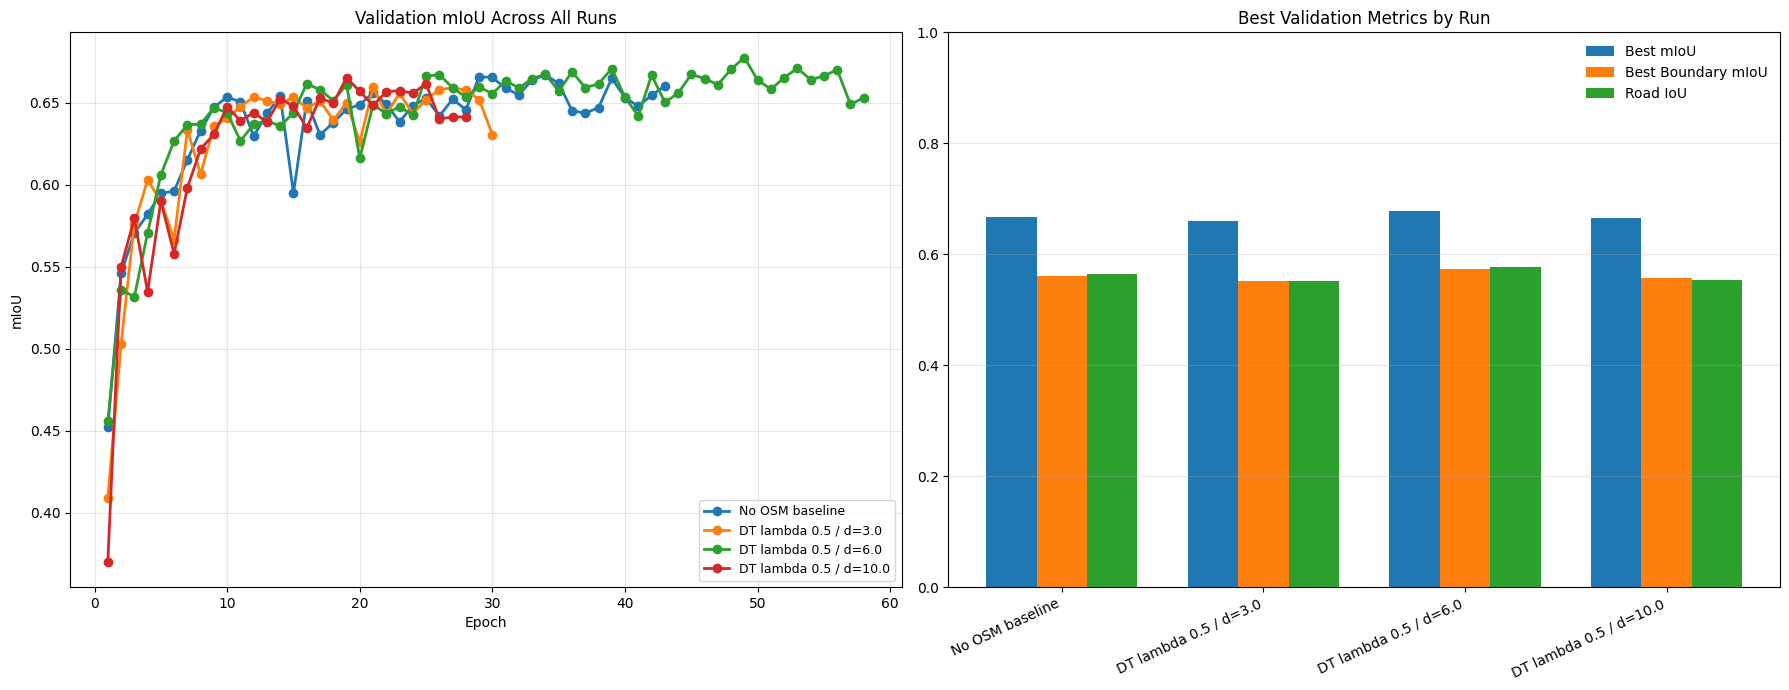

Saved summary plot to: /kaggle/working/sam2unet_augmented_osm_run/training_summary_all_runs.png

TRAINING SUMMARY ALL RUNS
Run                               OSM       Lambda    DT Max    Best Epoch  Best mIoU   Best BIoU   Road IoU  
No OSM baseline                   No        N/A       N/A       34          0.6671      0.5615      0.5636    
DT lambda 0.5 / d=3.0             Yes       0.5       3.0       21          0.6595      0.5515      0.5520    
DT lambda 0.5 / d=6.0             Yes       0.5       6.0       49          0.6777      0.5727      0.5777    
DT lambda 0.5 / d=10.0            Yes       0.5       10.0      19          0.6654      0.5570      0.5536    


In [6]:
run_names = list(history_all.keys())
if not run_names:
    raise RuntimeError('No training runs were collected.')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for run_name in run_names:
    run_info = history_all[run_name]
    hist = run_info['history']
    epochs = [row['epoch'] for row in hist if row['miou'] is not None]
    miou_vals = [row['miou'] for row in hist if row['miou'] is not None]
    if not epochs:
        continue
    axes[0].plot(epochs, miou_vals, marker='o', linewidth=2, label=run_info['label'])

axes[0].set_title('Validation mIoU Across All Runs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('mIoU')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='best', fontsize=9)

summary_rows = []
for run_name in run_names:
    run_info = history_all[run_name]
    valid_hist = [row for row in run_info['history'] if row['miou'] is not None]
    best_row = max(valid_hist, key=lambda row: row['miou']) if valid_hist else None
    summary_rows.append({
        'name': run_info['label'],
        'best_epoch': run_info['best_epoch'],
        'best_miou': run_info['best_miou'],
        'best_bmiou': best_row['bmiou'] if best_row is not None else np.nan,
        'road_iou': best_row['road_iou'] if best_row is not None else np.nan,
        'use_osm_data': run_info['use_osm_data'],
        'lambda_osm': run_info['lambda_osm'],
        'dt_max_distance': run_info['dt_max_distance'],
    })

x = np.arange(len(summary_rows))
width = 0.25
axes[1].bar(x - width, [row['best_miou'] for row in summary_rows], width, label='Best mIoU')
axes[1].bar(x, [row['best_bmiou'] for row in summary_rows], width, label='Best Boundary mIoU')
axes[1].bar(x + width, [row['road_iou'] for row in summary_rows], width, label='Road IoU')
axes[1].set_xticks(x)
axes[1].set_xticklabels([row['name'] for row in summary_rows], rotation=25, ha='right')
axes[1].set_ylim(0, 1.0)
axes[1].set_title('Best Validation Metrics by Run')
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend(frameon=False)

plt.tight_layout()
plot_path = WORK_DIR / 'training_summary_all_runs.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved summary plot to: {plot_path}')

print('\n' + '=' * 100)
print('TRAINING SUMMARY ALL RUNS')
print('=' * 100)
print(f"{'Run':<34}{'OSM':<10}{'Lambda':<10}{'DT Max':<10}{'Best Epoch':<12}{'Best mIoU':<12}{'Best BIoU':<12}{'Road IoU':<10}")
for row in summary_rows:
    osm_text = 'No' if not row['use_osm_data'] else 'Yes'
    lambda_text = 'N/A' if not row['use_osm_data'] else f"{row['lambda_osm']:.1f}"
    dt_text = 'N/A' if row['dt_max_distance'] is None else f"{row['dt_max_distance']:.1f}"
    print(f"{row['name']:<34}{osm_text:<10}{lambda_text:<10}{dt_text:<10}{str(row['best_epoch']):<12}{row['best_miou']:<12.4f}{row['best_bmiou']:<12.4f}{row['road_iou']:<10.4f}")

comparison_payload = {
    'runs': [
        {
            'name': history_all[name]['name'],
            'label': history_all[name]['label'],
            'lambda_osm': history_all[name]['lambda_osm'],
            'use_osm_data': history_all[name]['use_osm_data'],
            'dt_max_distance': history_all[name]['dt_max_distance'],
            'best_epoch': history_all[name]['best_epoch'],
            'best_miou': history_all[name]['best_miou'],
            'final_metrics': history_all[name]['final_metrics'],
        }
        for name in run_names
    ]
}
with open(WORK_DIR / 'training_summary_all_runs.json', 'w', encoding='utf-8') as handle:
    json.dump(comparison_payload, handle, indent=2)